## Group 2
#### Elias Bergset, Ludvik Høibjerg-Aslaksen, Viktor Mattias Larøi Hedman

### Imports

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [107]:
lifestyle_df = pd.read_csv(r"train.csv")
lifestyle_df = lifestyle_df.drop(columns="id")
pass # Avoids jupyter notebook displaying dataframe

### EDA

In [108]:
lifestyle_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 367500 entries, 0 to 367499
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           345653 non-null  float64
 1   sleep_duration_hrs            340323 non-null  float64
 2   sleep_quality_score           357702 non-null  float64
 3   cardio_mins_wk                355386 non-null  float64
 4   water_intake_liters           358969 non-null  float64
 5   screen_time_recreational_hrs  338865 non-null  float64
 6   social_media_hrs              362207 non-null  float64
 7   blood_pressure_sys            357789 non-null  float64
 8   diet_ultra_processed_pct      354171 non-null  float64
 9   diet_omega3_freq              344987 non-null  float64
 10  smoking_status                342146 non-null  str    
 11  alcohol_drinks_wk             346938 non-null  float64
 12  novel_learning_hrs_wk         340773 non-null  float64


Many entries are missing a value or multiple values

In [109]:
lifestyle_df_NaN = lifestyle_df.dropna()
lifestyle_df_NaN.info()

<class 'pandas.DataFrame'>
Index: 170275 entries, 8 to 367499
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           170275 non-null  float64
 1   sleep_duration_hrs            170275 non-null  float64
 2   sleep_quality_score           170275 non-null  float64
 3   cardio_mins_wk                170275 non-null  float64
 4   water_intake_liters           170275 non-null  float64
 5   screen_time_recreational_hrs  170275 non-null  float64
 6   social_media_hrs              170275 non-null  float64
 7   blood_pressure_sys            170275 non-null  float64
 8   diet_ultra_processed_pct      170275 non-null  float64
 9   diet_omega3_freq              170275 non-null  float64
 10  smoking_status                170275 non-null  str    
 11  alcohol_drinks_wk             170275 non-null  float64
 12  novel_learning_hrs_wk         170275 non-null  float64
 13  

Removing all rows with a NaN value removes about half the dataset. To resolve this an imputer is used the pipeline below

In [110]:
lifestyle_df.describe()

,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
count,345653.000000,340323.000000,357702.000000,355386.000000,358969.000000,338865.000000,362207.000000,357789.000000,354171.000000,344987.000000,346938.000000,340773.000000,342627.000000,349571.000000,367500.000000
mean,44.734089,7.100915,8.258727,98.868537,2.201164,5.509037,2.757720,126.222164,50.019510,1.863169,3.081012,2.268003,6.944966,5.973044,27.817293
std,17.178694,1.291474,1.919521,138.695219,0.715956,2.930716,2.174297,13.173230,23.564208,1.878462,6.186425,2.505047,2.275089,2.792521,1.801869
min,-129.000000,-5.934089,-11.000000,-1300.000000,-5.009674,-24.112509,-19.159991,-7.000000,-187.354820,-17.000000,-59.000000,-23.025042,-16.000000,-22.000000,17.000000
25%,34.000000,6.400000,7.000000,24.000000,1.800000,3.800000,1.300000,119.000000,36.500000,1.000000,0.000000,1.000000,6.000000,4.000000,27.000000
50%,44.000000,7.100000,8.000000,54.000000,2.200000,5.500000,2.400000,126.000000,50.000000,2.000000,1.000000,1.600000,7.000000,6.000000,28.000000
75%,55.000000,7.800000,10.000000,122.000000,2.600000,7.200000,3.900000,134.000000,63.600000,3.000000,4.000000,2.800000,8.000000,8.000000,29.000000
max,218.000000,20.139134,28.000000,1497.000000,9.402479,35.090503,24.661864,259.000000,287.389128,21.000000,65.000000,27.562680,30.000000,34.000000,30.000000


In [111]:
lifestyle_df.head(5)

,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
0,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
1,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
2,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
3,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
4,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


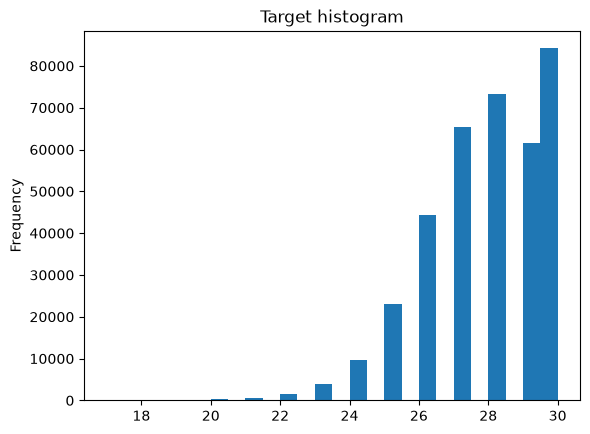

The amount of target values above 30 are 0
The amount of target values below 5 are 0


In [112]:
lifestyle_df["target"].plot.hist(bins=26, title="Target histogram")
plt.show()

print(f"The amount of target values above 30 are {len(lifestyle_df.loc[lifestyle_df["target"] > 30])}")
print(f"The amount of target values below 5 are {len(lifestyle_df.loc[lifestyle_df["target"] < 5])}")

Most values seem to be between 26 and 30, and the distribution is clearly skewed towards 30

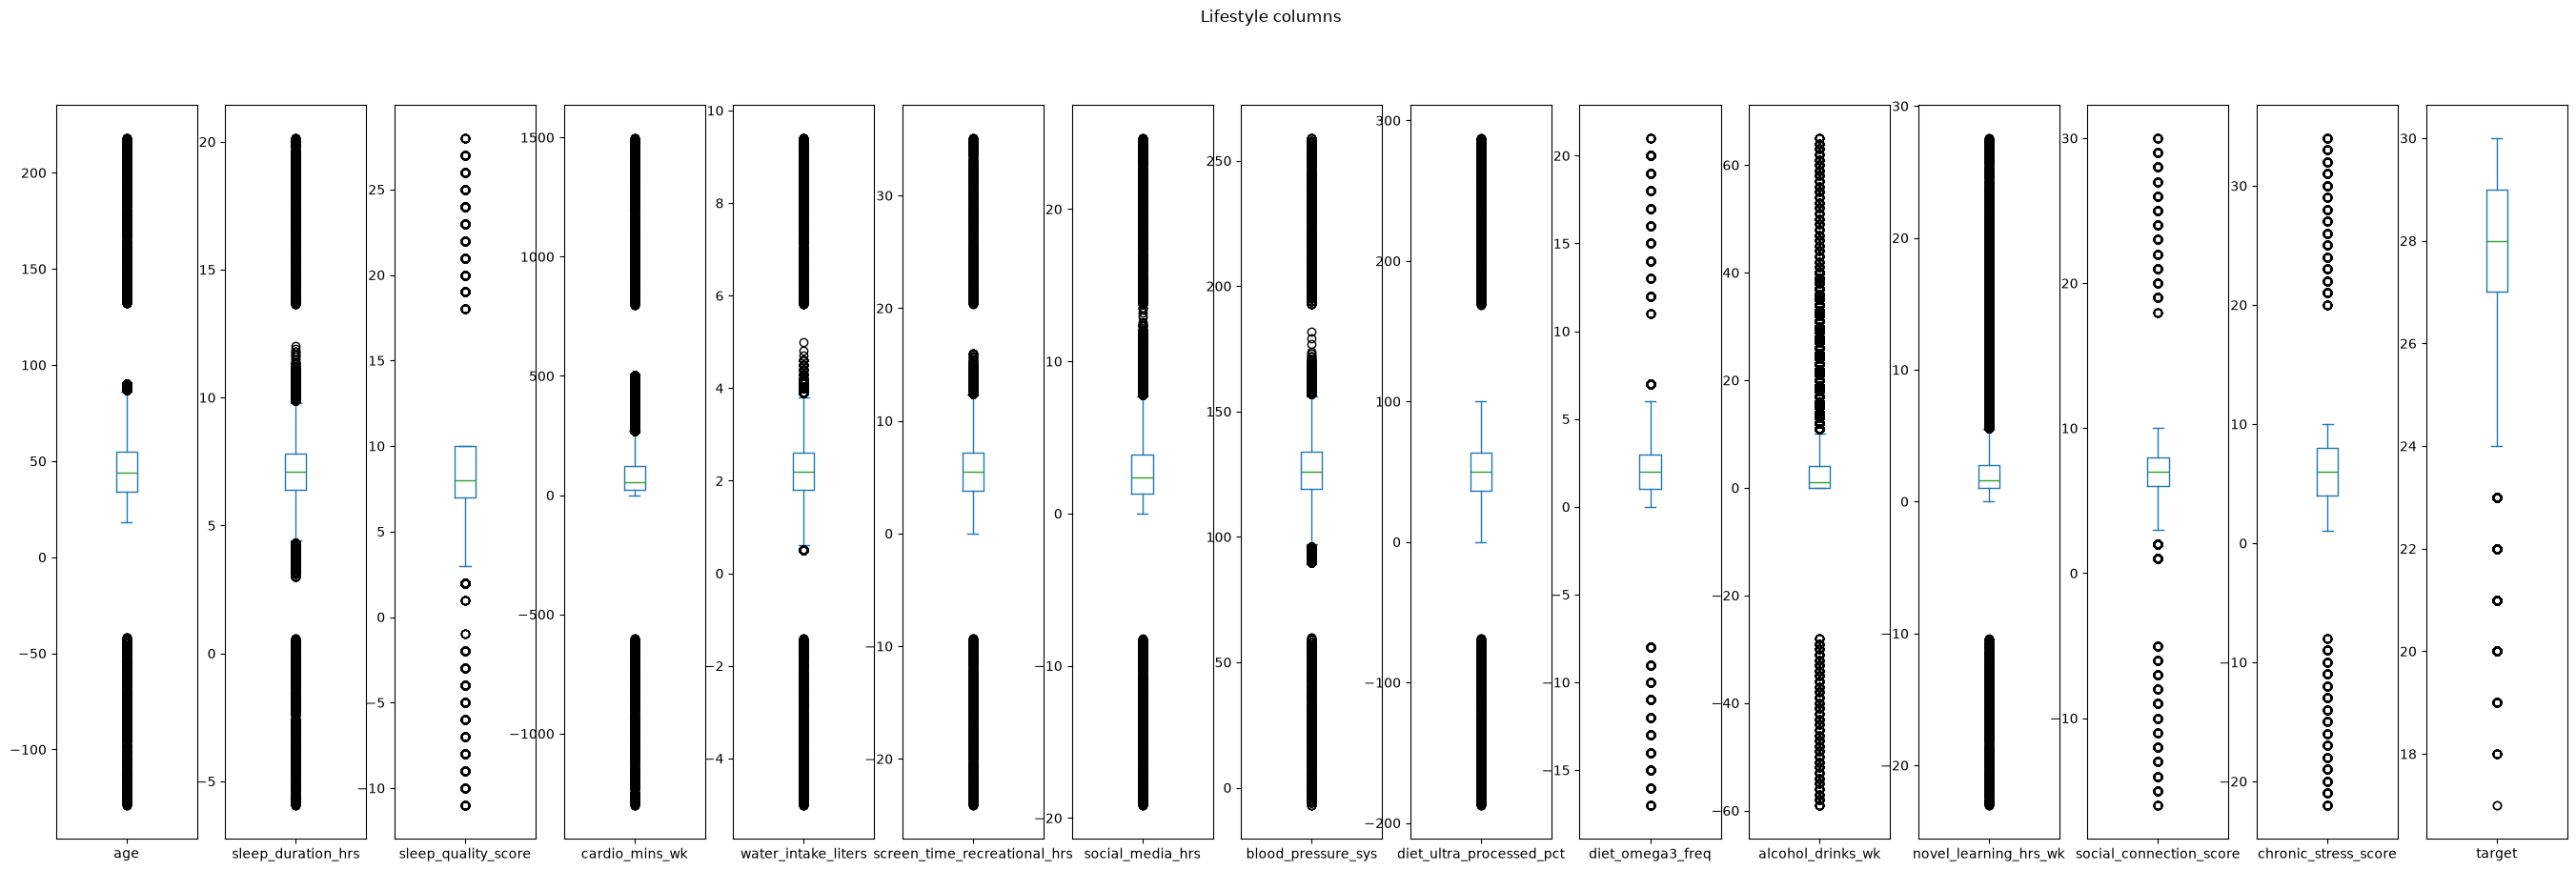

In [113]:
lifestyle_df.plot.box(subplots=True, figsize=(34, 10), title="Lifestyle columns")
plt.show()

Age: Most values seem to lie between about 20 and 50, some outliers exceed 100 years which seems to be invalid data. Age also contains negative values which are invalid and should be removed.

Sleep duration hrs: A fair assumption is to assumne all values around and below 0 are invalid, as a sleeping a single hour is unrealistic and from the values around 0 there is a huge gap between the next outliers which suggest the values around 0 are invalid. The same gap is seen at the upper values, so it is safe to assume all values above about 14 are invalid.

Sleep_quality_score: The score ranges from 1 to 10 so all values outside this range are invalid.

Cardio_mins_wk: Negative values are invalid as the smallest possible value is 0. Outliers above 500 here are possible to unlikely which values above 500 can be disregarded.

All negative values can be disregarded, and is not mentioned further

Water_intake_liters: Recommended daily water water intake for an adult ranges from 2.7 liters to 3.7 liters. Which makes the values greater than 6 possible but not realistic. Recommended range also includes water intake from sources other than just drinking, so the higher values seem very unrealistic when this is just a measurement of water intake. Values higher than 4 can be disregarded. ([Source](https://www.mayoclinic.org/healthy-lifestyle/nutrition-and-healthy-eating/in-depth/water/art-20044256))

Screen_time_recreational_hrs: Around 16 hours is realistic extreme for screen time all values above that seem invalid.

Social_media_hrs: It would make sense that social media hours follow screen time recreational hours somewhat, but slightly lower which is visible. 12 hours seems like a reasonable cutoff for this metric.

blood_pressure_sys: Systolic blood pressure between 90-120 is considered normal, but the data contains values as low as 60 and much higher than 180 which is considered an emergency. Values above 185 and values below 55 can be safely disregarded.([Source](https://my.clevelandclinic.org/health/diagnostics/17649-blood-pressure))

diet_ultra_processed_pct: Values are capped between 0-100, so all values outside this range are invalid. It is not unreasonable to assume that individuals can be in the extremes of that range.

diet_omega3_freq: Values are capped to 0-7 all values outside this range are invalid.

alcohol_drinks_wk: Drinking more than 14 drinks a week is considered a risk for your health. It is not unreasonable to assume that it is possible for someone to drink around 60 drinks, but the values are most likely incorrect therefore a compromise could to cap the the value to 30. ([Source](https://www.nhs.uk/live-well/alcohol-advice/the-risks-of-drinking-too-much/))

novel_learning_hrs_wk: For working adults, which would probably dominate this dataset a range of 2-4 hours seems reasonable, but it is not unreasonable to see values as high as 14 for an uemployed person or a student. Therefore a cap of 16 seems viable.

social_connection_score: All values outside 1-10 are invalid

chronic_stress_score: All values outside 1-10 are invalid

In [114]:
# Check for duplicates
lifestyle_df[lifestyle_df.duplicated()]

,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
3352,48.0,7.800000,9.0,54.0,2.1,5.3,3.4,122.0,19.7,2.0,Never,4.0,3.7,8.0,3.0,30
5294,70.0,8.000000,10.0,39.0,2.8,8.7,8.0,133.0,17.9,1.0,Former,2.0,1.3,6.0,2.0,27
6512,46.0,6.500000,10.0,164.0,1.6,7.6,5.1,131.0,42.7,0.0,Never,10.0,4.7,6.0,1.0,30
6908,56.0,6.100000,6.0,34.0,2.2,3.7,2.2,132.0,64.4,4.0,Never,0.0,1.4,4.0,8.0,27
7442,21.0,8.400000,8.0,42.0,1.5,4.2,3.7,108.0,37.8,3.0,Never,0.0,NaN,8.0,10.0,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
367471,48.0,NaN,8.0,75.0,2.3,5.5,2.5,137.0,42.0,0.0,Never,1.0,0.6,6.0,8.0,30
367472,50.0,7.800000,7.0,27.0,NaN,9.9,3.6,123.0,33.3,7.0,Never,1.0,1.1,10.0,7.0,29
367475,NaN,NaN,8.0,25.0,2.1,6.2,4.8,122.0,51.0,1.0,Never,23.0,2.1,10.0,10.0,26
367483,58.0,7.400000,10.0,148.0,NaN,8.8,2.3,144.0,42.5,0.0,Current,1.0,0.6,NaN,6.0,26


The dataset contains around 17500 duplicate rows

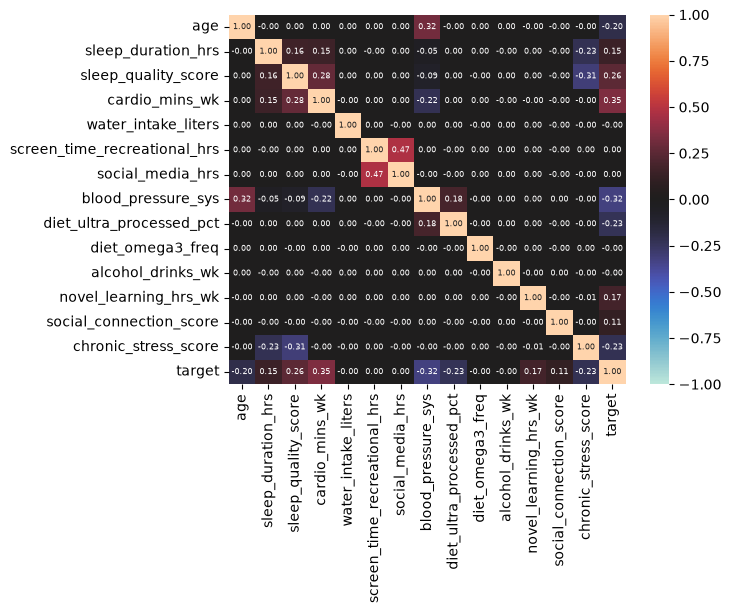

In [115]:
sns.heatmap(lifestyle_df.corr(numeric_only=True), annot=True, vmin=-1, vmax=1, center=0, fmt=".2f", annot_kws={"size": 6})
plt.show()

In [116]:
lifestyle_df.groupby(by="smoking_status").median(numeric_only=True)


,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
smoking_status,,,,,,,,,,,,,,,
Current,45.0,7.1,8.0,54.0,2.2,5.5,2.4,135.0,50.2,2.0,1.0,1.6,7.0,6.0,27.0
Former,44.0,7.1,8.0,54.0,2.2,5.5,2.4,125.0,49.9,2.0,1.0,1.6,7.0,6.0,28.0
Never,44.0,7.1,8.0,54.0,2.2,5.5,2.4,125.0,50.1,2.0,1.0,1.6,7.0,6.0,28.0


Every value median grouped by smoking_status are the same or very close except blood pressure which shows an elevated value and target which scores lower by one point in current smokers.

### Data cleaning

In [117]:
# Remove all duplicate rows
lifestyle_cleaned_df = lifestyle_df.copy()
lifestyle_cleaned_df = lifestyle_cleaned_df.drop_duplicates()

In [118]:
# Change all excess values described above to NaN
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["age"] > 100) | (lifestyle_cleaned_df["age"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["sleep_duration_hrs"] > 14) | (lifestyle_cleaned_df["sleep_duration_hrs"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["sleep_quality_score"] > 10) | (lifestyle_cleaned_df["sleep_quality_score"] < 1)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["cardio_mins_wk"] > 500) | (lifestyle_cleaned_df["cardio_mins_wk"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["water_intake_liters"] > 4) | (lifestyle_cleaned_df["water_intake_liters"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["screen_time_recreational_hrs"] > 16) | (lifestyle_cleaned_df["screen_time_recreational_hrs"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["social_media_hrs"] > 12) | (lifestyle_cleaned_df["social_media_hrs"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["blood_pressure_sys"] > 185) | (lifestyle_cleaned_df["blood_pressure_sys"] < 55)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["diet_ultra_processed_pct"] > 100) | (lifestyle_cleaned_df["diet_ultra_processed_pct"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["diet_omega3_freq"] > 7) | (lifestyle_cleaned_df["diet_omega3_freq"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["alcohol_drinks_wk"] > 30) | (lifestyle_cleaned_df["alcohol_drinks_wk"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["novel_learning_hrs_wk"] > 16) | (lifestyle_cleaned_df["novel_learning_hrs_wk"] < 0)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["social_connection_score"] > 10) | (lifestyle_cleaned_df["social_connection_score"] < 1)] = np.nan
lifestyle_cleaned_df.loc[(lifestyle_cleaned_df["chronic_stress_score"] > 10) | (lifestyle_cleaned_df["chronic_stress_score"] < 1)] = np.nan


lifestyle_cleaned_df.info()

<class 'pandas.DataFrame'>
Index: 350000 entries, 0 to 367499
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           305116 non-null  float64
 1   sleep_duration_hrs            300444 non-null  float64
 2   sleep_quality_score           315826 non-null  float64
 3   cardio_mins_wk                313772 non-null  float64
 4   water_intake_liters           316905 non-null  float64
 5   screen_time_recreational_hrs  299120 non-null  float64
 6   social_media_hrs              319795 non-null  float64
 7   blood_pressure_sys            315930 non-null  float64
 8   diet_ultra_processed_pct      312701 non-null  float64
 9   diet_omega3_freq              304523 non-null  float64
 10  smoking_status                302084 non-null  str    
 11  alcohol_drinks_wk             306079 non-null  float64
 12  novel_learning_hrs_wk         300746 non-null  float64
 13  

### Pipelines

In [119]:
# Pipeline imports
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline 
from sklearn.linear_model import LogisticRegression, ElasticNet
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import TunedThresholdClassifierCV, train_test_split
from sklearn.base import clone

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

In [120]:
# Make column transforms
replace_NaN = ColumnTransformer(transformers=[
    ("cat", SimpleImputer(strategy ="most_frequent"), ["smoking_status"]),
    ("num", SimpleImputer(strategy="median"), lifestyle_cleaned_df.drop(columns="smoking_status").columns),
], remainder ='passthrough')

convert_to_numeric = ColumnTransformer(transformers =[
    ('enc', OneHotEncoder(drop ='first'), 0),
], remainder ='passthrough')

##### Pipeline A

In [ ]:
pipe_A = Pipeline([
    ("r_NaN", replace_NaN),
    ("ctn", convert_to_numeric),
    ('scaler', StandardScaler()),
    ("elasticnet", ElasticNet())
    ])

params = {
    'pca__n_components': [0.80, 0.85, 0.90, 0.95, 0.99, None],   
    'svc__C': np.logspace(-2, 3, 10),
    'svc__gamma': np.logspace(-4, 1, 10),
    'elasticnet__random_state': 42,
}

cv = KFold(n_splits=10, random_state=42)

cv = GridSearchCV(pipe_A, params, cv=cv)

TypeError: GridSearchCV.__init__() missing 2 required positional arguments: 'estimator' and 'param_grid'